# 08 — Compare classification models for a route-demand watchlist

## Decision question
For a carrier, route, and month, can we flag records likely to land in the historically high-demand group so a planner can **review** them? This is a screening signal, not an instruction to add flights. BTS reports monthly market passengers, not schedules, seat capacity, fares, or live bookings.

This lab completes the workbook classification experiments on the same BTS task: Logistic Regression, K-Nearest Neighbors, Gaussian Naive Bayes, Support Vector Machine, and Decision Tree. We train on 2025 and evaluate on 2026 records. The high-demand threshold is calculated from 2025 only to avoid using future labels. A stratified sample keeps the comparison usable on a student computer; change `SAMPLE_PER_YEAR` to scale it.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, confusion_matrix)

ROOT=Path.cwd(); df=pd.read_csv(ROOT/'data/processed/air_passenger_monthly.csv')
SAMPLE_PER_YEAR=6000  # raise for more data; SVC cost grows quickly
required={'PASSENGERS','DISTANCE','YEAR','MONTH','ORIGIN','DEST','UNIQUE_CARRIER'}
assert required.issubset(df.columns), f"Missing columns: {required-set(df.columns)}"
df['MONTH_SIN']=np.sin(2*np.pi*df.MONTH/12); df['MONTH_COS']=np.cos(2*np.pi*df.MONTH/12)
train0=df[df.YEAR.eq(2025)].copy(); test0=df[df.YEAR.eq(2026)].copy()
threshold=float(train0.PASSENGERS.quantile(.75))
train0['HIGH_DEMAND']=(train0.PASSENGERS>=threshold).astype(int); test0['HIGH_DEMAND']=(test0.PASSENGERS>=threshold).astype(int)
print(f"2025 train records={len(train0):,}; 2026 test records={len(test0):,}; threshold={threshold:,.0f} passengers")
print("This 2026 extract is partial-year. Report the exact months available before interpreting scores.")
# Stratify so both classes are represented. Use deterministic sampling; preserve test as an untouched evaluation set.
def stratified_cap(frame, limit, seed):
    # Preserve natural class proportions; do not balance the evaluation data.
    pieces=[]
    for label, group in frame.groupby('HIGH_DEMAND'):
        n=min(len(group), max(1, round(limit*len(group)/len(frame))))
        pieces.append(group.sample(n=n, random_state=seed))
    return pd.concat(pieces).sample(frac=1, random_state=seed).reset_index(drop=True)
train=stratified_cap(train0,SAMPLE_PER_YEAR,42)
test=stratified_cap(test0,SAMPLE_PER_YEAR,43)
print(f'Sampled train={len(train):,} (high={train.HIGH_DEMAND.mean():.1%}); test={len(test):,} (high={test.HIGH_DEMAND.mean():.1%})')
cat=['ORIGIN','DEST','UNIQUE_CARRIER']; num=['DISTANCE','MONTH_SIN','MONTH_COS']
X_train=train[cat+num]; y_train=train.HIGH_DEMAND
X_test=test[cat+num]; y_test=test.HIGH_DEMAND
prep=ColumnTransformer([('category',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',min_frequency=5))]),cat),
                        ('number',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num)])
models={
 'Logistic Regression': LogisticRegression(max_iter=1000,class_weight='balanced'),
 'KNN (k=7)': KNeighborsClassifier(n_neighbors=7,weights='distance'),
 'Gaussian Naive Bayes': GaussianNB(),
 'SVM (linear)': LinearSVC(C=0.5,class_weight='balanced',dual='auto',max_iter=3000,random_state=42),
 'Decision Tree': DecisionTreeClassifier(max_depth=12,min_samples_leaf=20,class_weight='balanced',random_state=42),
}
results=[]; fitted={}
for name,model in models.items():
    pipe=Pipeline([('prepare',clone(prep)),('model',model)])
    # Dense input is needed by GaussianNB and SVC; transform only the modest sampled data.
    if name=='Gaussian Naive Bayes':
        from sklearn.preprocessing import FunctionTransformer
        pipe=Pipeline([('prepare',clone(prep)),('dense',FunctionTransformer(lambda x:x.toarray() if hasattr(x,'toarray') else x)),('model',model)])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    score=pipe.predict_proba(X_test)[:,1] if hasattr(pipe,'predict_proba') else pipe.decision_function(X_test)
    row={'model':name,'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred,zero_division=0),
         'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0),
         'roc_auc':roc_auc_score(y_test,score)}
    results.append(row); fitted[name]=pipe
leaderboard=pd.DataFrame(results).sort_values('f1',ascending=False).reset_index(drop=True)
display(leaderboard.round(3))


2025 train records=317,333; 2026 test records=185,891; threshold=4,310 passengers
This 2026 extract is partial-year. Report the exact months available before interpreting scores.
Sampled train=6,000 (high=25.0%); test=6,000 (high=24.7%)
                  model  accuracy  precision  recall     f1  roc_auc
0          SVM (linear)     0.737      0.481   0.820  0.606    0.853
1   Logistic Regression     0.737      0.481   0.818  0.606    0.855
2         Decision Tree     0.735      0.476   0.748  0.582    0.803
3             KNN (k=7)     0.799      0.603   0.548  0.574    0.827
4  Gaussian Naive Bayes     0.559      0.355   0.969  0.520    0.697


## Choose a model by the cost of a miss

For a review queue, **recall** answers “of the genuinely high-demand records, how many did we flag?” Precision answers “of the records we flagged, how many were high demand?” A false negative can hide a market worth investigating; a false positive creates extra analyst review. The best model depends on the review capacity, so inspect precision, recall, F1 and ROC-AUC together rather than declaring accuracy alone the winner.

The train/test split is chronological, which better represents forecasting future months than a random split. A stronger follow-up is rolling-origin validation across multiple years; the current 19-month dataset only has one complete training year and one partial test year.


Top F1 model for this sampled run: SVM (linear)
Use it only as a candidate for human review; do not treat the score as a flight-capacity recommendation.


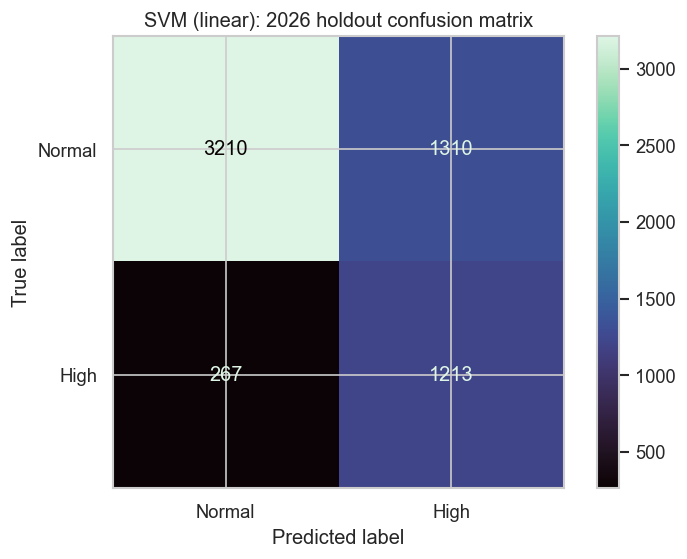

In [2]:
best_name=leaderboard.iloc[0].model
print("Top F1 model for this sampled run:",best_name)
print("Use it only as a candidate for human review; do not treat the score as a flight-capacity recommendation.")
ConfusionMatrixDisplay.from_estimator(fitted[best_name],X_test,y_test,display_labels=['Normal','High'],cmap='mako',values_format='d')
plt.title(f'{best_name}: 2026 holdout confusion matrix'); plt.tight_layout(); plt.show()


## Scaling this workflow

The code uses a single scikit-learn preprocessing pipeline so imputation, one-hot encoding and scaling are learned from training rows and applied consistently to test rows. Unknown airport/carrier categories are handled safely. Start with the 6,000-record stratified cap for a laptop; increase it for more stable estimates. RBF-SVM is the slowest model, so a production-scale deployment would require a larger compute budget or a linear SVM. Monthly aggregate data and limited history are the main limits, not the dashboard.
